# Cropland & Cropping-Season Mapping, Chakwal and Rawalpindi (crop year 2024-25)
**Multi-sensor (Sentinel-2 + Sentinel-1) Random Forest in Google Earth Engine, with independent manual validation**
*Light version: designed to run inside Earth Engine's restricted mode.*

**How to run:** run Cells 1 to 7 top to bottom, one at a time. Cell 4 is the slow one (it prints progress and retries smaller chunks if Earth Engine times out). Cell 8 creates a blind validation sheet. You label it in Excel (about 30 minutes), then run Cells 9 and 10.

**What it does**
1. Draws random points across both districts and extracts one crop year (Nov 2024 to Oct 2025) of features: monthly NDVI and annual bands from Sentinel-2, rabi/kharif radar from Sentinel-1, and terrain.
2. Trains Random Forest on Dynamic World labels and compares optical-only, SAR-only, optical + SAR and optical + SAR + terrain, with random and spatial-block cross-validation.
3. Estimates the area of six land-cover classes per district from the random sample, with 95% confidence intervals.
4. Splits cropland into cropping seasons (rabi only, kharif only, double, fallow/not sown) from NDVI phenology, with a threshold sensitivity test.
5. Gives you an independent accuracy estimate from points you label yourself on high-resolution imagery.

In [ ]:
# ===== CELL 1: setup (edit ONLY the project ID) =====
GEE_PROJECT = 'YOUR-GEE-PROJECT-ID'   # replace with 'YOUR-GEE-PROJECT-ID' before uploading to GitHub

import ee, os, json, math, shutil, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)
os.makedirs('outputs', exist_ok=True)
print('Earth Engine ready')

Earth Engine ready


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


In [ ]:
# ===== CELL 2: study area and settings =====
DISTRICTS = ['Chakwal', 'Rawalpindi']
START, END = '2024-11-01', '2025-11-01'      # one crop year: rabi 2024-25 + kharif 2025
MONTHS = ['Nov','Dec','Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct']
SEED = 42
CLASS_NAMES = ['Water', 'Trees', 'Rangeland/shrub', 'Cropland', 'Built-up', 'Bare']
CROP = 3
PALETTE = ['1f78b4', '1b7837', 'b8a86b', 'f2c94c', 'd62728', '9e9e9e']

def get_districts():
    gaul = (ee.FeatureCollection('FAO/GAUL/2015/level2')
            .filter(ee.Filter.eq('ADM0_NAME', 'Pakistan'))
            .filter(ee.Filter.inList('ADM2_NAME', DISTRICTS)))
    if gaul.size().getInfo() == len(DISTRICTS):
        return gaul, 'ADM2_NAME'
    gb = (ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2')
          .filter(ee.Filter.eq('shapeGroup', 'PAK'))
          .filter(ee.Filter.inList('shapeName', DISTRICTS)))
    if gb.size().getInfo() == len(DISTRICTS):
        return gb, 'shapeName'
    raise ValueError('Could not find both district polygons. Check the district names in DISTRICTS.')

districts, NAME_PROP = get_districts()
roi = districts.geometry()
names = districts.aggregate_array(NAME_PROP).getInfo()
dgeom = {nm: districts.filter(ee.Filter.eq(NAME_PROP, nm)).geometry() for nm in names}
print('Districts:', names, '| total area km2:', round(roi.area(1).divide(1e6).getInfo()))

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)
/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


Districts: ['Rawalpindi', 'Chakwal'] | total area km2: 12406


In [ ]:
# ===== CELL 3: features (Sentinel-2, Sentinel-1, terrain) and labels (Dynamic World) =====
cs_plus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
s2_raw = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(roi).filterDate(START, END)
          .linkCollection(cs_plus, ['cs_cdf']))

def mask_s2(img):
    refl = img.select(['B2', 'B3', 'B4', 'B8', 'B11', 'B12']).divide(10000)
    return refl.updateMask(img.select('cs_cdf').gte(0.6)).copyProperties(img, ['system:time_start'])

def add_idx(img):
    return img.addBands([
        img.normalizedDifference(['B8', 'B4']).rename('NDVI'),
        img.normalizedDifference(['B11', 'B8']).rename('NDBI'),
        img.normalizedDifference(['B3', 'B11']).rename('MNDWI')])

annual = add_idx(s2_raw.map(mask_s2).median())

t0 = ee.Date(START)
ndvi_bands = []
for i, mname in enumerate(MONTHS):
    d0, d1 = t0.advance(i, 'month'), t0.advance(i + 1, 'month')
    m = add_idx(s2_raw.filterDate(d0, d1).map(mask_s2).median()).select('NDVI')
    # months with no clear pixels are filled with the annual median NDVI
    ndvi_bands.append(m.unmask(annual.select('NDVI')).rename('NDVI_' + mname))

opt = ee.Image.cat(ndvi_bands + [annual.select(['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDBI', 'MNDWI'])])

s1 = (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(roi).filterDate(START, END)
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .select(['VV', 'VH']))
def s1_med(a, b, tag):
    return s1.filterDate(a, b).median().rename(['VV_' + tag, 'VH_' + tag])
sar = ee.Image.cat([s1_med('2024-12-01', '2025-04-01', 'rabi'),
                    s1_med('2025-07-01', '2025-10-01', 'kharif')])

dem = ee.Image('USGS/SRTMGL1_003')
topo = ee.Image.cat([dem.rename('elev'), ee.Terrain.slope(dem).rename('slope')])

full = opt.addBands(sar).addBands(topo)
OPT_BANDS = opt.bandNames().getInfo()
SAR_BANDS = sar.bandNames().getInfo()
TOPO_BANDS = ['elev', 'slope']

# Dynamic World yearly mode as automatic labels, merged to 6 classes
dw = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(roi)
      .filterDate(START, END).select('label').mode())
labels = dw.remap([0, 1, 2, 4, 5, 6, 7], [0, 1, 2, 3, 2, 4, 5]).rename('class')
print(len(OPT_BANDS), 'optical bands,', len(SAR_BANDS), 'SAR bands,', len(TOPO_BANDS), 'terrain bands')

20 optical bands, 4 SAR bands, 2 terrain bands


In [ ]:
# ===== CELL 4: random point sample with all features and labels (small chunks, auto-retry) =====
import time
N_PER_DISTRICT = 1800      # random points per district
CHUNK = 300                # points per Earth Engine request (halves automatically if a request times out)
stack = full.addBands(labels)

def sample_chunk(nm, n, seed):
    pts = ee.FeatureCollection.randomPoints(region=dgeom[nm], points=n, seed=seed)
    return stack.sampleRegions(collection=pts, scale=20, geometries=True, tileScale=16).getInfo()['features']

rows = []
for nm in names:
    done, seed, chunk, fails = 0, 1000, CHUNK, 0
    while done < N_PER_DISTRICT:
        t = time.time()
        try:
            feats = sample_chunk(nm, chunk, seed)
        except Exception as e:
            fails += 1
            chunk = max(60, chunk // 2)
            print(f'  {nm}: request failed ({str(e)[:70]}). Retrying with {chunk} points...')
            if fails > 10:
                raise
            time.sleep(5); seed += 1
            continue
        for f in feats:
            r = dict(f['properties'])
            r['lon'], r['lat'] = f['geometry']['coordinates']
            r['district'] = nm
            rows.append(r)
        done += chunk; seed += 1
        print(f'{nm}: {done}/{N_PER_DISTRICT} points requested ({time.time() - t:.0f} s)')

df = pd.DataFrame(rows).dropna().reset_index(drop=True)
df['class'] = df['class'].astype(int)
df.to_csv('outputs/random_points_features.csv', index=False)
print('\n', len(df), 'usable points')
print(df['class'].map(dict(enumerate(CLASS_NAMES))).value_counts())

Rawalpindi: 300/1800 points requested (42 s)
Rawalpindi: 600/1800 points requested (22 s)
Rawalpindi: 900/1800 points requested (22 s)
Rawalpindi: 1200/1800 points requested (24 s)
Rawalpindi: 1500/1800 points requested (26 s)
Rawalpindi: 1800/1800 points requested (26 s)
Chakwal: 300/1800 points requested (38 s)
Chakwal: 600/1800 points requested (48 s)
Chakwal: 900/1800 points requested (47 s)
Chakwal: 1200/1800 points requested (46 s)
Chakwal: 1500/1800 points requested (52 s)
Chakwal: 1800/1800 points requested (47 s)

 3598 usable points
class
Cropland           1369
Trees               726
Rangeland/shrub     619
Built-up            584
Bare                269
Water                31
Name: count, dtype: int64


,features,cv,accuracy,macro_F1,cropland_F1
0,Optical only,random,0.651,0.623,0.735
1,Optical only,spatial block,0.645,0.611,0.728
2,SAR only,random,0.501,0.429,0.656
3,SAR only,spatial block,0.501,0.435,0.659
4,Optical + SAR,random,0.669,0.646,0.756
5,Optical + SAR,spatial block,0.667,0.635,0.754
6,Optical + SAR + terrain,random,0.678,0.663,0.762
7,Optical + SAR + terrain,spatial block,0.679,0.657,0.763


Best feature set by spatial-block accuracy: Optical + SAR + terrain


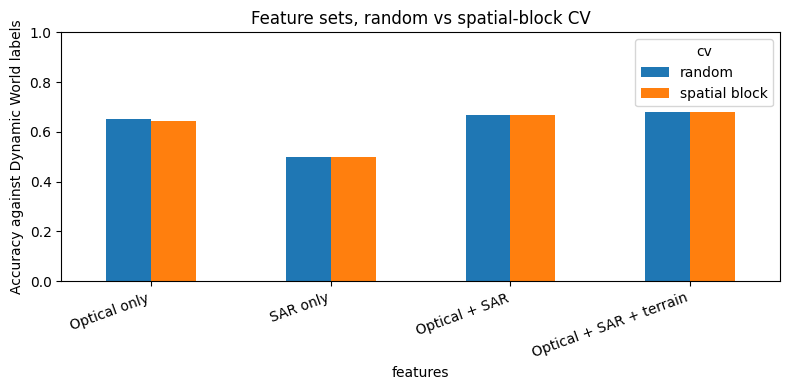

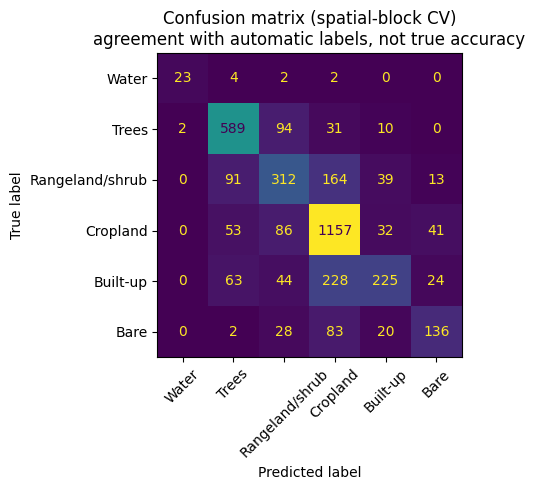

In [ ]:
# ===== CELL 5: classifier benchmark: sensor combinations, random vs spatial-block CV =====
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

# ~5 km spatial blocks (0.05 degrees)
df['block'] = (np.floor(df['lon'] / 0.05).astype(int).astype(str) + '_' +
               np.floor(df['lat'] / 0.05).astype(int).astype(str))
y = df['class'].values
sets = {
    'Optical only': OPT_BANDS,
    'SAR only': SAR_BANDS,
    'Optical + SAR': OPT_BANDS + SAR_BANDS,
    'Optical + SAR + terrain': OPT_BANDS + SAR_BANDS + TOPO_BANDS,
}
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=SEED)
res, preds = [], {}
for sname, cols in sets.items():
    X = df[cols].values
    for cvname, cv, grp in [('random', KFold(5, shuffle=True, random_state=SEED), None),
                            ('spatial block', GroupKFold(5), df['block'])]:
        p = cross_val_predict(rf, X, y, cv=cv, groups=grp)
        preds[(sname, cvname)] = p
        res.append({'features': sname, 'cv': cvname,
                    'accuracy': round(accuracy_score(y, p), 3),
                    'macro_F1': round(f1_score(y, p, average='macro', zero_division=0), 3),
                    'cropland_F1': round(f1_score(y == CROP, p == CROP), 3)})
bench = pd.DataFrame(res)
bench.to_csv('outputs/benchmark_results.csv', index=False)
display(bench)

spatial = bench[bench['cv'] == 'spatial block'].set_index('features')['accuracy']
best_name = spatial.idxmax()
BEST_BANDS = sets[best_name]
df['pred'] = preds[(best_name, 'spatial block')]      # out-of-fold (spatial-block) predictions for every point
print('Best feature set by spatial-block accuracy:', best_name)

piv = bench.pivot(index='features', columns='cv', values='accuracy').loc[list(sets)]
piv.plot(kind='bar', figsize=(8, 4), ylim=(0, 1))
plt.ylabel('Accuracy against Dynamic World labels'); plt.xticks(rotation=20, ha='right')
plt.title('Feature sets, random vs spatial-block CV'); plt.tight_layout()
plt.savefig('outputs/fig_benchmark.png', dpi=200); plt.show()

present = sorted(set(y) | set(df['pred']))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, df['pred'], labels=present,
                                        display_labels=[CLASS_NAMES[i] for i in present],
                                        ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title('Confusion matrix (spatial-block CV)\nagreement with automatic labels, not true accuracy')
plt.tight_layout(); plt.savefig('outputs/fig_confusion.png', dpi=200); plt.show()

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


,district,class,share_%,area_km2,95%_CI_km2,n_points
0,Rawalpindi,Water,0.8,50,25,1798
1,Chakwal,Water,0.6,36,22,1800
2,Both districts,Water,0.7,86,33,3598
3,Rawalpindi,Trees,32.8,1963,130,1798
4,Chakwal,Trees,11.8,759,96,1800
5,Both districts,Trees,21.9,2722,161,3598
6,Rawalpindi,Rangeland/shrub,9.2,550,80,1798
7,Chakwal,Rangeland/shrub,22.3,1429,123,1800
8,Both districts,Rangeland/shrub,16.0,1979,147,3598
9,Rawalpindi,Cropland,42.4,2539,137,1798


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


  map at 800px failed (400 Client Error: Bad Request for url: https://earthengine.googleapis.), trying smaller...


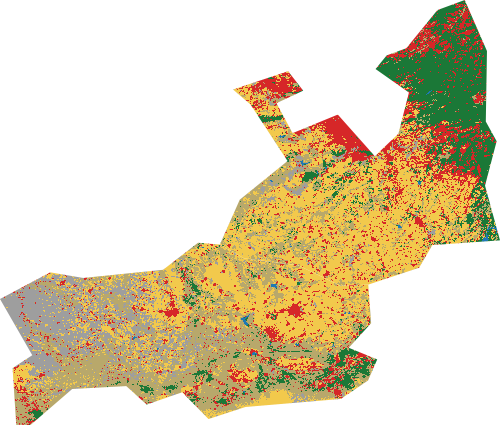

Legend: {'Water': '1f78b4', 'Trees': '1b7837', 'Rangeland/shrub': 'b8a86b', 'Cropland': 'f2c94c', 'Built-up': 'd62728', 'Bare': '9e9e9e'}


In [ ]:
# ===== CELL 6: area estimates from the random sample (with 95% CI) + land-cover map =====
Z = 1.96
A = {nm: dgeom[nm].area(1).divide(1e6).getInfo() for nm in names}      # district areas, km2
Atot = sum(A.values())

rows = []
for k, cname in enumerate(CLASS_NAMES):
    comb_p, comb_var = 0.0, 0.0
    for nm in names:
        sub = df[df['district'] == nm]; n = len(sub)
        p = float((sub['pred'] == k).mean())
        comb_p += A[nm] / Atot * p
        comb_var += (A[nm] / Atot) ** 2 * p * (1 - p) / n
        rows.append({'district': nm, 'class': cname, 'share_%': round(100 * p, 1),
                     'area_km2': round(p * A[nm]), '95%_CI_km2': round(Z * math.sqrt(p * (1 - p) / n) * A[nm]),
                     'n_points': n})
    rows.append({'district': 'Both districts', 'class': cname, 'share_%': round(100 * comb_p, 1),
                 'area_km2': round(comb_p * Atot), '95%_CI_km2': round(Z * math.sqrt(comb_var) * Atot),
                 'n_points': len(df)})
    if k == CROP:
        W_CROP = comb_p
area_df = pd.DataFrame(rows)
area_df.to_csv('outputs/landcover_areas.csv', index=False)
display(area_df)
json.dump({'W_crop': W_CROP}, open('outputs/map_weights.json', 'w'))

# map image (nice to have; skipped automatically if Earth Engine is too slow)
def save_thumb(img, vis, fname, dims=(800, 500)):
    for dim in dims:
        try:
            url = img.getThumbURL({**vis, 'region': roi, 'dimensions': dim, 'format': 'png'})
            r = requests.get(url, timeout=900); r.raise_for_status()
            with open(fname, 'wb') as fh: fh.write(r.content)
            display(Image(fname)); return True
        except Exception as e:
            print(f'  map at {dim}px failed ({str(e)[:70]}), trying smaller...')
    print('Map image skipped (Earth Engine too slow right now). The tables and figures are unaffected.')
    return False

try:
    train_df = df.groupby('class').head(300)
    train_fc = ee.FeatureCollection([
        ee.Feature(None, {**{b: float(r[b]) for b in BEST_BANDS}, 'class': int(r['class'])})
        for _, r in train_df.iterrows()])
    rf_ee = ee.Classifier.smileRandomForest(200, seed=SEED).train(train_fc, 'class', BEST_BANDS)
    classified = full.select(BEST_BANDS).classify(rf_ee).rename('class').clip(roi)
    save_thumb(classified, {'min': 0, 'max': 5, 'palette': PALETTE}, 'outputs/map_landcover_2024_25.png')
    print('Legend:', dict(zip(CLASS_NAMES, PALETTE)))
except Exception as e:
    print('Map step skipped:', str(e)[:120])

ndvi_threshold,0.40,0.45,0.50
season_class,,,
Fallow / not sown,15.9,23.6,33.1
Rabi only (winter crop),13.9,14.0,13.0
Kharif only (summer crop),37.7,38.9,38.2
Double cropped,32.5,23.5,15.7


Main result uses threshold 0.45; 0.40 and 0.50 show the sensitivity.


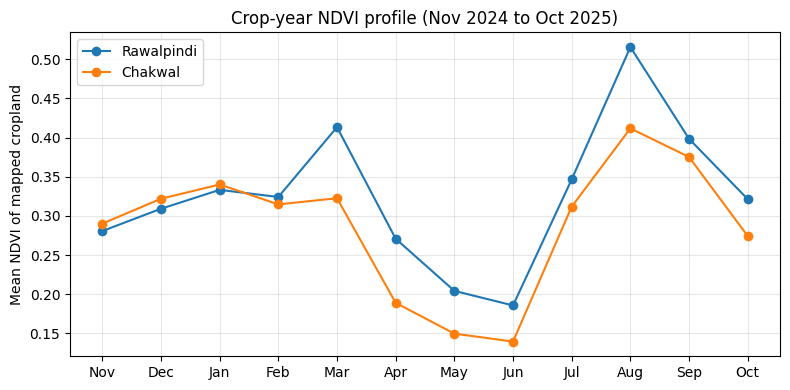

In [ ]:
# ===== CELL 7: cropping seasons from NDVI phenology + monitoring chart (from the random sample) =====
RABI = ['Dec', 'Jan', 'Feb', 'Mar', 'Apr']
KHARIF = ['Jul', 'Aug', 'Sep', 'Oct']
CAL_NAMES = ['Fallow / not sown', 'Rabi only (winter crop)', 'Kharif only (summer crop)', 'Double cropped']
crop_df = df[df['pred'] == CROP].copy()
rabi_max = crop_df[['NDVI_' + m for m in RABI]].max(axis=1)
kharif_max = crop_df[['NDVI_' + m for m in KHARIF]].max(axis=1)

def seasons(thr):
    r, k = (rabi_max >= thr).values, (kharif_max >= thr).values
    return np.select([r & ~k, k & ~r, r & k], [1, 2, 3], default=0)

rows = []
for thr in (0.40, 0.45, 0.50):
    crop_df['season'] = seasons(thr)
    comb = np.zeros(4)
    for nm in names:
        sub_all = df[df['district'] == nm]; sub = crop_df[crop_df['district'] == nm]
        crop_area = float((sub_all['pred'] == CROP).mean()) * A[nm]
        for k in range(4):
            s = float((sub['season'] == k).mean()) if len(sub) else 0.0
            comb[k] += s * crop_area
            rows.append({'ndvi_threshold': thr, 'district': nm, 'season_class': CAL_NAMES[k],
                         'share_of_cropland_%': round(100 * s, 1), 'area_km2': round(s * crop_area),
                         'n_cropland_points': len(sub)})
    for k in range(4):
        rows.append({'ndvi_threshold': thr, 'district': 'Both districts', 'season_class': CAL_NAMES[k],
                     'share_of_cropland_%': round(100 * comb[k] / comb.sum(), 1), 'area_km2': round(comb[k]),
                     'n_cropland_points': len(crop_df)})
season_df = pd.DataFrame(rows)
season_df.to_csv('outputs/cropping_season_areas.csv', index=False)
display(season_df[season_df['district'] == 'Both districts'].pivot(
    index='season_class', columns='ndvi_threshold', values='share_of_cropland_%').loc[CAL_NAMES])
print('Main result uses threshold 0.45; 0.40 and 0.50 show the sensitivity.')

plt.figure(figsize=(8, 4))
for nm in names:
    prof = crop_df[crop_df['district'] == nm][['NDVI_' + m for m in MONTHS]].mean()
    plt.plot(MONTHS, prof.values, marker='o', label=nm)
plt.ylabel('Mean NDVI of mapped cropland'); plt.title('Crop-year NDVI profile (Nov 2024 to Oct 2025)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('outputs/fig_ndvi_profile.png', dpi=200); plt.show()

In [ ]:
# ===== CELL 8: create a BLIND validation sheet (cropland vs not cropland) =====
pool_crop = df[df['pred'] == CROP]
pool_other = df[df['pred'] != CROP]
v = pd.concat([pool_crop.sample(n=min(60, len(pool_crop)), random_state=7).assign(map_class='crop'),
               pool_other.sample(n=min(60, len(pool_other)), random_state=7).assign(map_class='not_crop')])
v = v[['lat', 'lon', 'map_class']].round({'lat': 6, 'lon': 6}).sample(frac=1, random_state=1).reset_index(drop=True)
v.insert(0, 'id', range(1, len(v) + 1))
v['google_maps_link'] = [f'https://www.google.com/maps/@{la},{lo},250m/data=!3m1!1e3'
                         for la, lo in zip(v['lat'], v['lon'])]
v['your_label'] = ''
v[['id', 'lat', 'lon', 'google_maps_link', 'your_label']].to_csv('outputs/validation_sheet_BLIND.csv', index=False)
v[['id', 'map_class']].to_csv('outputs/validation_key_DO_NOT_OPEN.csv', index=False)
print(len(v), 'points saved. Download outputs/validation_sheet_BLIND.csv from the Files panel (left side).')

120 points saved. Download outputs/validation_sheet_BLIND.csv from the Files panel (left side).


## How to label the validation sheet (about 30 minutes)
1. Download `validation_sheet_BLIND.csv` from the Colab Files panel and open it in Excel.
2. Open each `google_maps_link` (satellite view is already on, centered on the point).
3. Type **crop** in `your_label` if the point is on an agricultural field (cultivated, or a fallow field with clear field boundaries). Type **not_crop** for anything else (trees, built-up, bare land, rangeland, water). Type **unsure** if you really cannot tell; those rows are skipped.
4. **Do not open** `validation_key_DO_NOT_OPEN.csv`. Labeling blind is what makes the accuracy honest.
5. Save the file as CSV and run Cell 9.

In [12]:
# ===== CELL 9: independent accuracy from your manual labels =====
from google.colab import files
up = files.upload()                      # choose your filled validation sheet (.xlsx or .csv)
fname = list(up.keys())[0]
if fname.lower().endswith(('.xlsx', '.xls')):
    lab = pd.read_excel(fname)
else:
    lab = pd.read_csv(fname, encoding='utf-8-sig')
lab.columns = [str(c).strip().lower() for c in lab.columns]
key = pd.read_csv('outputs/validation_key_DO_NOT_OPEN.csv')
w = json.load(open('outputs/map_weights.json'))

d = lab.merge(key, on='id')
d['your_label'] = d['your_label'].astype(str).str.strip().str.lower()
print('Labeled:', int(d['your_label'].isin(['crop', 'not_crop']).sum()),
      '| unsure/blank skipped:', int((~d['your_label'].isin(['crop', 'not_crop'])).sum()))
d = d[d['your_label'].isin(['crop', 'not_crop'])]

cls = ['crop', 'not_crop']
W = {'crop': w['W_crop'], 'not_crop': 1 - w['W_crop']}
n = pd.crosstab(d['map_class'], d['your_label']).reindex(index=cls, columns=cls, fill_value=0)
ni = n.sum(axis=1)
p = {(i, j): (W[i] * n.loc[i, j] / ni[i] if ni[i] > 0 else 0.0) for i in cls for j in cls}
OA = sum(p[(c, c)] for c in cls)
UA = {c: (n.loc[c, c] / ni[c] if ni[c] > 0 else np.nan) for c in cls}
PA = {c: (p[(c, c)] / sum(p[(i, c)] for i in cls) if sum(p[(i, c)] for i in cls) > 0 else np.nan) for c in cls}

print('\nConfusion matrix (rows = map, columns = your label)'); display(n)
print(f'Area-weighted overall accuracy (cropland vs not): {OA:.3f}')
print(f"Cropland user's accuracy (of mapped cropland, share that is cropland): {UA['crop']:.3f}")
print(f"Cropland producer's accuracy (of true cropland, share that was mapped): {PA['crop']:.3f}")
pd.DataFrame({'metric': ['overall_accuracy_area_weighted', 'cropland_users_accuracy',
                         'cropland_producers_accuracy', 'n_points'],
              'value': [OA, UA['crop'], PA['crop'], len(d)]}).to_csv('outputs/validation_accuracy.csv', index=False)

Saving validation_sheet_LABEL_ME.xlsx to validation_sheet_LABEL_ME (1).xlsx
Labeled: 114 | unsure/blank skipped: 6

Confusion matrix (rows = map, columns = your label)


your_label,crop,not_crop
map_class,,
crop,46,10
not_crop,15,43


Area-weighted overall accuracy (cropland vs not): 0.779
Cropland user's accuracy (of mapped cropland, share that is cropland): 0.821
Cropland producer's accuracy (of true cropland, share that was mapped): 0.733


In [13]:
print('--- BENCHMARK ---')
print(pd.read_csv('outputs/benchmark_results.csv').to_string(index=False))
a = pd.read_csv('outputs/landcover_areas.csv')
print('\n--- LAND COVER AREAS (both districts) ---')
print(a[a['district'] == 'Both districts'].to_string(index=False))
s = pd.read_csv('outputs/cropping_season_areas.csv')
print('\n--- CROPPING SEASONS (both districts) ---')
print(s[s['district'] == 'Both districts'].to_string(index=False))
print('\n--- VALIDATION ---')
print(pd.read_csv('outputs/validation_accuracy.csv').to_string(index=False))

--- BENCHMARK ---
               features            cv  accuracy  macro_F1  cropland_F1
           Optical only        random     0.651     0.623        0.735
           Optical only spatial block     0.645     0.611        0.728
               SAR only        random     0.501     0.429        0.656
               SAR only spatial block     0.501     0.435        0.659
          Optical + SAR        random     0.669     0.646        0.756
          Optical + SAR spatial block     0.667     0.635        0.754
Optical + SAR + terrain        random     0.678     0.663        0.762
Optical + SAR + terrain spatial block     0.679     0.657        0.763

--- LAND COVER AREAS (both districts) ---
      district           class  share_%  area_km2  95%_CI_km2  n_points
Both districts           Water      0.7        86          33      3598
Both districts           Trees     21.9      2722         161      3598
Both districts Rangeland/shrub     16.0      1979         147      3598
Both distric

In [ ]:
# ===== CELL 10: zip everything for GitHub =====
shutil.make_archive('crop_project_outputs', 'zip', 'outputs')
from google.colab import files
files.download('crop_project_outputs.zip')

## Limitations (copy into your README and StoryMap)
- Training labels are Dynamic World, an automatic product derived from optical imagery. Cross-validation scores measure agreement with those labels, not true accuracy. The manual validation in Cells 8 and 9 is the independent check.
- Areas are estimated from a simple random sample of points (about 1,800 per district) with 95% confidence intervals, not counted pixel by pixel. Predictions at each point are out-of-fold (spatial-block) predictions.
- The manual validation is small (120 points), covers cropland vs not cropland only, and Google Maps imagery dates may not match 2024-25.
- Crop **types** (wheat, maize, groundnut and so on) are not mapped. Without field labels they cannot be separated reliably, so the project maps cropland and cropping seasons instead.
- Cropping-season classes use NDVI thresholds that are assumptions, not field-validated. The sensitivity table shows how much the result depends on them.
- One crop year only. Months with no clear Sentinel-2 pixels were filled with the annual median NDVI.

In [14]:
# ===== error-adjusted cropland area (uses your manual validation) =====
p_true = sum(W[i] * n.loc[i, 'crop'] / ni[i] for i in cls)
var = sum(W[i]**2 * (n.loc[i, 'crop'] / ni[i]) * (1 - n.loc[i, 'crop'] / ni[i]) / (ni[i] - 1) for i in cls)
ci = 1.96 * math.sqrt(var)
print(f'Mapped cropland share:         {100*W["crop"]:.1f}%  ({W["crop"]*Atot:,.0f} km2)')
print(f'Error-adjusted cropland share: {100*p_true:.1f}% +/- {100*ci:.1f}%')
print(f'Error-adjusted cropland area:  {p_true*Atot:,.0f} +/- {ci*Atot:,.0f} km2')
pd.DataFrame({'metric': ['mapped_share', 'adjusted_share', 'adjusted_95CI', 'adjusted_area_km2', 'adjusted_CI_km2'],
              'value': [W['crop'], p_true, ci, p_true*Atot, ci*Atot]}).to_csv('outputs/cropland_area_adjusted.csv', index=False)

Mapped cropland share:         46.4%  (5,757 km2)
Error-adjusted cropland share: 52.0% +/- 7.7%
Error-adjusted cropland area:  6,448 +/- 954 km2
